In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

import warnings
warnings.filterwarnings('ignore')

In [2]:
# Dictionary to store the history of the improvements
experiment_results = {}

In [3]:
# Load target variable
y = pd.read_parquet('../data/raw/y_train.parquet')

In [4]:
# Load Clusters from Notebook 1
df_clusters = pd.read_parquet('../data/processed/cluster_labels.parquet')
df_clusters = df_clusters.set_index('id')

In [5]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
base_xgb = xgb.XGBClassifier(
    n_estimators=300, 
    learning_rate=0.05, 
    max_depth=5, 
    subsample=0.8, 
    colsample_bytree=0.8, 
    enable_categorical=True,
    eval_metric='auc',
    scale_pos_weight=2.43795,
    random_state=42, 
    n_jobs=-1
)

In [6]:
# ==============================================================================
# EXPERIMENT 1: The Baseline (Raw tsfresh features + Clusters)
# ==============================================================================
features_baseline = pd.read_parquet('../data/processed/features_baseline.parquet')

# Merge Baseline with Clusters
X_exp1 = features_baseline.join(df_clusters)
X_exp1['Cluster_ID'] = X_exp1['Cluster_ID'].astype('category')

# Align with target
X_exp1 = X_exp1.loc[y.index]

scores_exp1 = cross_val_score(base_xgb, X_exp1, y, cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
experiment_results['1. Baseline (Raw + Clusters)'] = np.mean(scores_exp1)
print(f"Baseline Mean ROC AUC: {np.mean(scores_exp1):.4f} (+/- {np.std(scores_exp1):.4f})")

Baseline Mean ROC AUC: 0.6620 (+/- 0.0049)


In [7]:
# ==============================================================================
# EXPERIMENT 2: Interaction Features (Adding Ratios & Diffs)
# ==============================================================================
features_interactions = pd.read_parquet('../data/processed/features_interactions.parquet')

# Add interactions to the previous dataset
X_exp2 = pd.concat([X_exp1, features_interactions], axis=1)
X_exp2 = X_exp2.loc[y.index]

scores_exp2 = cross_val_score(base_xgb, X_exp2, y, cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
experiment_results['2. Interactions (Ratios/Diffs)'] = np.mean(scores_exp2)
print(f"Interactions Mean ROC AUC: {np.mean(scores_exp2):.4f} (+/- {np.std(scores_exp2):.4f})")

Interactions Mean ROC AUC: 0.7134 (+/- 0.0050)


In [8]:
# ==============================================================================
# EXPERIMENT 3: Physical Transformations (Adding CUMSUM)
# ==============================================================================
features_cumsum = pd.read_parquet('../data/processed/features_cumsum.parquet')

# Create the MEGA dataset combining everything
X_exp3 = pd.concat([X_exp2, features_cumsum], axis=1)
X_exp3 = X_exp3.loc[y.index]

scores_exp3 = cross_val_score(base_xgb, X_exp3, y, cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
experiment_results['3. Physical Transf. (CUMSUM)'] = np.mean(scores_exp3)
print(f"CUMSUM Mean ROC AUC: {np.mean(scores_exp3):.4f} (+/- {np.std(scores_exp3):.4f})")

CUMSUM Mean ROC AUC: 0.7256 (+/- 0.0057)


In [9]:
# ==============================================================================
# EXPERIMENT 4: Feature Selection (Top 500)
# ==============================================================================
# Fit the model once on the mega dataset to get feature importances
base_xgb.fit(X_exp3, y)

importances = base_xgb.feature_importances_
df_importances = pd.DataFrame({'Feature': X_exp3.columns, 'Importance': importances})
df_importances = df_importances.sort_values(by='Importance', ascending=False)

# Keep only Top 500
top_500_features = df_importances.head(500)['Feature'].tolist()
X_exp4_top500 = X_exp3[top_500_features]

scores_exp4 = cross_val_score(base_xgb, X_exp4_top500, y, cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
experiment_results['4. Feature Selection (Top 500)'] = np.mean(scores_exp4)
print(f"Top 500 Mean ROC AUC: {np.mean(scores_exp4):.4f} (+/- {np.std(scores_exp4):.4f})")

Top 500 Mean ROC AUC: 0.7627 (+/- 0.0056)


In [10]:
df_importances = df_importances.sort_values(by='Importance', ascending=False).reset_index(drop=True)

for col in ['Cluster_ID', 'magic_cv_full']:
    if col in df_importances['Feature'].values:
        rank = df_importances[df_importances['Feature'] == col].index[0]
        weight = df_importances[df_importances['Feature'] == col]['Importance'].values[0]
        print(f"Variable '{col}' is in position #{rank + 1} of importance (Weight: {weight:.4f})")

Variable 'Cluster_ID' is in position #385 of importance (Weight: 0.0004)
Variable 'magic_cv_full' is in position #71 of importance (Weight: 0.0007)


In [11]:
# ==============================================================================
# EXPERIMENT 5: Feature Selection (Top 200)
# ==============================================================================
# Keep only Top 200 from the previously calculated importances
top_200_features = df_importances.head(200)['Feature'].tolist()
X_exp5_top200 = X_exp3[top_200_features]

scores_exp5 = cross_val_score(base_xgb, X_exp5_top200, y, cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
experiment_results['5. Feature Selection (Top 200)'] = np.mean(scores_exp5)
print(f"Top 200 Mean ROC AUC: {np.mean(scores_exp5):.4f} (+/- {np.std(scores_exp5):.4f})")

Top 200 Mean ROC AUC: 0.7690 (+/- 0.0051)


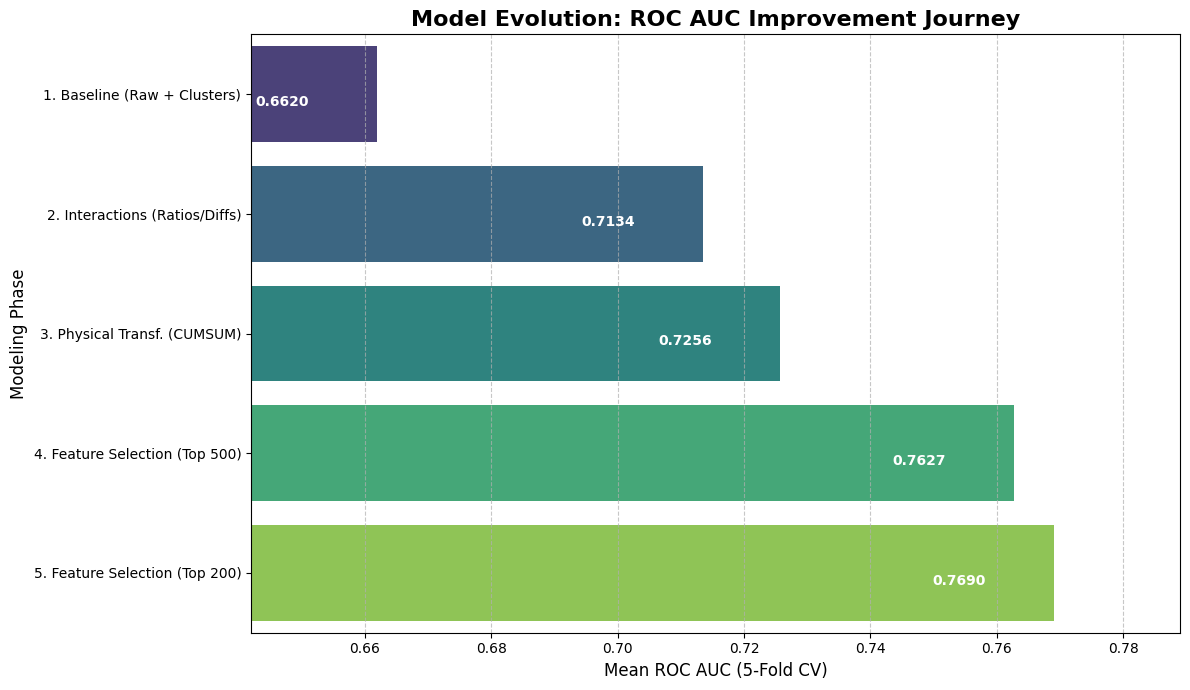

In [12]:
plt.figure(figsize=(12, 7))
results_df = pd.DataFrame(list(experiment_results.items()), columns=['Experiment', 'ROC_AUC'])

# Create a barplot showing the evolution
ax = sns.barplot(x='ROC_AUC', y='Experiment', data=results_df, palette='viridis')

# Add the text with the exact score on each bar
for p in ax.patches:
    width = p.get_width()
    plt.text(width - 0.015, p.get_y() + p.get_height()/2. + 0.1, 
             f'{width:.4f}', ha="center", color='white', fontweight='bold')

plt.title("Model Evolution: ROC AUC Improvement Journey", fontsize=16, fontweight='bold')
plt.xlabel("Mean ROC AUC (5-Fold CV)", fontsize=12)
plt.ylabel("Modeling Phase", fontsize=12)

# Adjust X-axis limits to highlight the differences
min_score = results_df['ROC_AUC'].min()
max_score = results_df['ROC_AUC'].max()
plt.xlim(min_score - 0.02, max_score + 0.02) 

plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


CLASSIFICATION REPORT (5-Fold CV)
              precision    recall  f1-score   support

       False     0.8167    0.8631    0.8392      7092
        True     0.6125    0.5277    0.5669      2909

    accuracy                         0.7655     10001
   macro avg     0.7146    0.6954    0.7031     10001
weighted avg     0.7573    0.7655    0.7600     10001



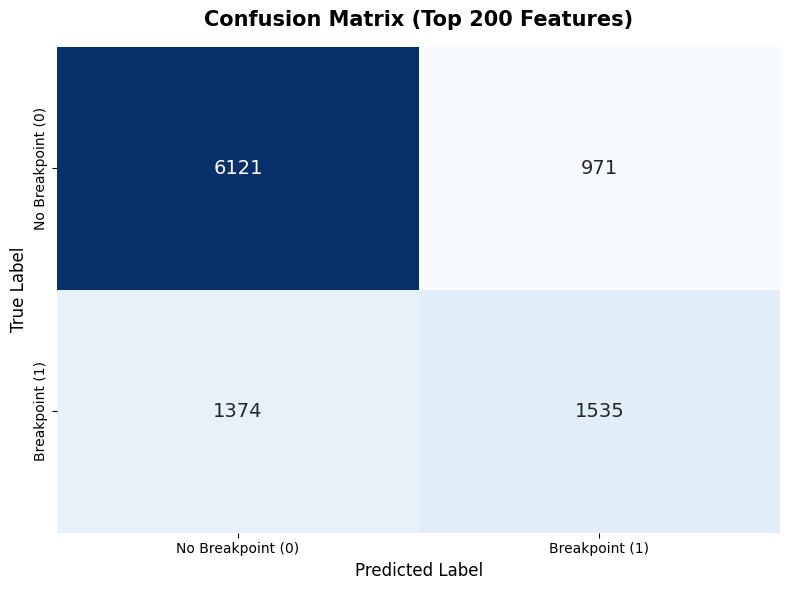

In [13]:
# We use the X_exp5_top200 from your last experiment
# cross_val_predict returns the actual predicted labels (0 or 1) for the entire dataset
y_pred_cv = cross_val_predict(base_xgb, X_exp5_top200, y, cv=cv_strategy, n_jobs=-1)

# 1. Print Classification Report
print("\n" + "="*50)
print("CLASSIFICATION REPORT (5-Fold CV)")
print("="*50)
print(classification_report(y, y_pred_cv, digits=4))

# 2. Plot Confusion Matrix
cm = confusion_matrix(y, y_pred_cv)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Breakpoint (0)', 'Breakpoint (1)'],
            yticklabels=['No Breakpoint (0)', 'Breakpoint (1)'],
            annot_kws={"size": 14})

plt.title('Confusion Matrix (Top 200 Features)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

In [14]:
if 'Cluster_ID' not in X_exp5_top200.columns:
    X_exp5_top200 = X_exp5_top200.join(df_clusters)
    X_exp5_top200['Cluster_ID'] = X_exp5_top200['Cluster_ID'].astype('category')

save_path = '../data/processed/features_top200.parquet'
X_exp5_top200.to_parquet(save_path)